<a href="https://colab.research.google.com/github/scottn66/vgg11/blob/main/vgg11_from_scratch_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VGG11 from scratch

Rebuild **VGG11** (Simonyan & Zisserman 2014, config A) in PyTorch, adding BatchNorm after each conv, and train it from scratch on a **20-class ImageNet subset** (6,000 train / 1,000 val images, 224×224).

**Result (run 1):** 75.9% val accuracy after 30 epochs (chance = 5%).

Contents: 1. Setup · 2. Data · 3. Model (built piece by piece) · 4. Sanity check: overfit one batch · 5. Training · 6. Optimizer visualization · 7. Results log

## 1. Setup

In [1]:
import os, time
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
RUNS = "/content/drive/MyDrive/vgg11/runs"
print(device)

cuda


## 2. Data
Copy the zips from Drive and unzip them to local disk (much faster reads than Drive).

In [2]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/data {RUNS}
!cp /content/drive/MyDrive/vgg11/data/imagenet_*20.zip /content/data/
%cd /content/data
!for z in imagenet_*20.zip; do unzip -q -o "$z"; done
!ls; ls imagenet_train20a | wc -l; ls imagenet_val20 | wc -l

Mounted at /content/drive
/content/data
imagenet_test20      imagenet_train20a	   imagenet_val20
imagenet_test20.zip  imagenet_train20.zip  imagenet_val20.zip
20
1000


Train is in `ImageFolder` layout (`<wnid>/img.JPEG`). Val is one flat folder, so the label comes from the filename prefix.

In [3]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
val_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder("/content/data/imagenet_train20a", transform=train_tf)


class FlatVal(Dataset):
    """Flat val folder; label = wnid prefix of the filename, e.g. n01737021_10767.JPEG."""

    def __init__(self, root, class_to_idx, tf):
        self.root, self.c2i, self.tf = root, class_to_idx, tf
        self.files = sorted(os.listdir(root))

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        name = self.files[i]
        label = self.c2i[name.split("_")[0]]
        img = Image.open(os.path.join(self.root, name)).convert("RGB")
        return self.tf(img), label


val_ds = FlatVal("/content/data/imagenet_val20", train_ds.class_to_idx, val_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True,  num_workers=2)
val_dl   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=2)

# check
print(len(train_ds), len(val_ds), len(train_ds.classes))   # expect 6000 1000 20
x, y = train_ds[0]; print(x.shape, y)                       # expect (3, 224, 224) 0

6000 1000 20
torch.Size([3, 224, 224]) 0


## 3. Model
### 3a. Building block: Conv → BatchNorm → ReLU
3×3 conv with `padding=1` keeps the spatial size. Params = 3·3·C_in·C_out + C_out (+ 2·C_out for BN).

In [4]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
    )

# check
b = conv_block(3, 64)
print(b(torch.randn(1, 3, 224, 224)).shape)       # expect (1, 64, 224, 224)
print(sum(p.numel() for p in b.parameters()))     # expect 1,920 (1,792 conv + 128 BN)

torch.Size([1, 64, 224, 224])
1920


### 3b. Feature extractor (config A)
8 conv layers, 5 max-pools (each halves H and W): 224 → 112 → 56 → 28 → 14 → 7.

In [5]:
def make_features():
    return nn.Sequential(
        conv_block(3, 64),                            nn.MaxPool2d(2, 2),   # 112
        conv_block(64, 128),                          nn.MaxPool2d(2, 2),   # 56
        conv_block(128, 256), conv_block(256, 256),   nn.MaxPool2d(2, 2),   # 28
        conv_block(256, 512), conv_block(512, 512),   nn.MaxPool2d(2, 2),   # 14
        conv_block(512, 512), conv_block(512, 512),   nn.MaxPool2d(2, 2),   # 7
    )

# check
f = make_features()
print(f(torch.randn(1, 3, 224, 224)).shape)     # expect (1, 512, 7, 7)
print(sum(p.numel() for p in f.parameters()))   # expect 9,225,984 (9,220,480 without BN)

torch.Size([1, 512, 7, 7])
9225984


### 3c. Classifier
Three fully connected layers. No softmax at the end: `CrossEntropyLoss` applies log-softmax itself.

In [6]:
def make_classifier(num_classes=20, dropout=0.0):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(512 * 7 * 7, 4096), nn.ReLU(inplace=True), nn.Dropout(dropout),
        nn.Linear(4096, 4096),        nn.ReLU(inplace=True), nn.Dropout(dropout),
        nn.Linear(4096, num_classes),
    )

# check
c = make_classifier()
print(c(torch.randn(1, 512, 7, 7)).shape)       # expect (1, 20)
print(sum(p.numel() for p in c.parameters()))   # expect 119,627,796

torch.Size([1, 20])
119627796


### 3d. Full VGG11

In [7]:
class VGG11(nn.Module):
    def __init__(self, num_classes=20, dropout=0.0):
        super().__init__()
        self.features = make_features()
        self.classifier = make_classifier(num_classes, dropout)

    def forward(self, x):
        return self.classifier(self.features(x))

# check
m = VGG11()
print(m(torch.randn(2, 3, 224, 224)).shape)     # expect (2, 20)
print(sum(p.numel() for p in m.parameters()))   # expect 128,853,780 (128,848,276 without BN)

torch.Size([2, 20])
128853780


## 4. Sanity check: overfit one batch
If the model can't drive the loss near 0 on 8 images, something is broken. (Without BatchNorm, this stalled for hundreds of steps.)

In [8]:
model = VGG11().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)

x, y = next(iter(train_dl))
x, y = x[:8].to(device), y[:8].to(device)

model.train()
for step in range(300):
    loss = criterion(model(x), y)
    optimizer.zero_grad()   # clear old gradients
    loss.backward()         # compute new gradients
    optimizer.step()        # update weights
    if step % 20 == 0:
        print(step, round(loss.item(), 4))

0 2.9655
20 0.0001
40 0.0
60 0.0
80 0.0
100 0.0
120 0.0
140 0.0
160 0.0
180 0.0
200 0.0
220 0.0
240 0.0
260 0.0
280 0.0


## 5. Training
SGD + momentum, weight decay, cosine learning-rate schedule. Saves the best checkpoint by val accuracy.

Change **one** setting per run and record it in the results log (section 7).

In [9]:
# ---- run config ----
EPOCHS       = 30
LR           = 0.01
DROPOUT      = 0.0    # paper uses 0.5
LABEL_SMOOTH = 0.0
RUN_NAME     = "run1_bn"
# --------------------

model = VGG11(dropout=DROPOUT).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


def evaluate(model, loader):
    model.eval()                          # BatchNorm uses running stats, dropout off
    correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(dim=1) == y).sum().item()
            total += y.size(0)
    return correct / total


history, best = [], 0.0
for epoch in range(EPOCHS):
    model.train()
    t0, running = time.time(), 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        loss = criterion(model(x), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        running += loss.item() * x.size(0)
    scheduler.step()                      # once per epoch

    train_loss = running / len(train_ds)
    val_acc = evaluate(model, val_dl)
    history.append((train_loss, val_acc))
    if val_acc > best:
        best = val_acc
        torch.save(model.state_dict(), f"{RUNS}/{RUN_NAME}_best.pt")
    print(f"epoch {epoch+1:2d}  loss {train_loss:.3f}  val acc {val_acc:.3f}  ({time.time()-t0:.0f}s)")

print(f"best val acc: {best:.3f}")

epoch  1  loss 2.605  val acc 0.182  (60s)
epoch  2  loss 2.345  val acc 0.301  (63s)
epoch  3  loss 2.189  val acc 0.366  (66s)
epoch  4  loss 2.068  val acc 0.319  (65s)
epoch  5  loss 1.952  val acc 0.374  (69s)
epoch  6  loss 1.883  val acc 0.454  (69s)
epoch  7  loss 1.818  val acc 0.445  (67s)
epoch  8  loss 1.744  val acc 0.453  (67s)
epoch  9  loss 1.653  val acc 0.477  (71s)
epoch 10  loss 1.575  val acc 0.520  (69s)
epoch 11  loss 1.521  val acc 0.458  (68s)
epoch 12  loss 1.460  val acc 0.546  (72s)
epoch 13  loss 1.420  val acc 0.591  (70s)
epoch 14  loss 1.352  val acc 0.624  (71s)
epoch 15  loss 1.285  val acc 0.587  (69s)
epoch 16  loss 1.243  val acc 0.623  (67s)
epoch 17  loss 1.186  val acc 0.645  (75s)
epoch 18  loss 1.135  val acc 0.650  (72s)
epoch 19  loss 1.077  val acc 0.687  (69s)
epoch 20  loss 1.030  val acc 0.670  (68s)
epoch 21  loss 0.978  val acc 0.701  (73s)
epoch 22  loss 0.934  val acc 0.715  (70s)
epoch 23  loss 0.913  val acc 0.728  (72s)
epoch 24  l

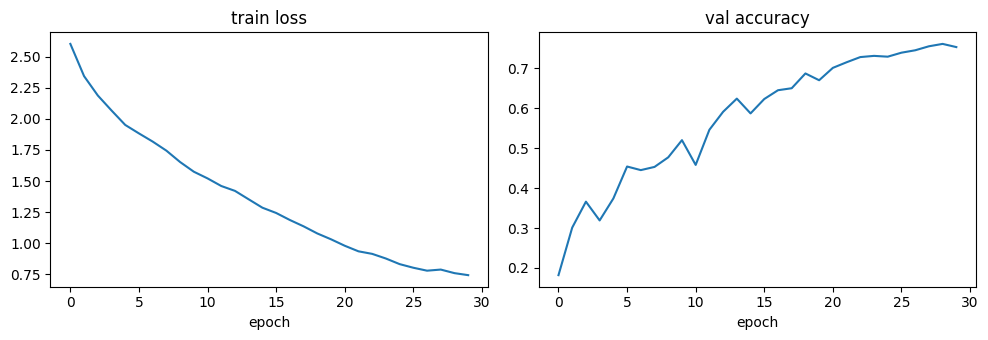

In [10]:
loss, acc = zip(*history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(loss); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(acc);  ax[1].set_title("val accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 6. Optimizer visualization
Paths of different optimizers on an elongated bowl, $L = 0.1x^2 + 2y^2$ (steep in y, shallow in x).

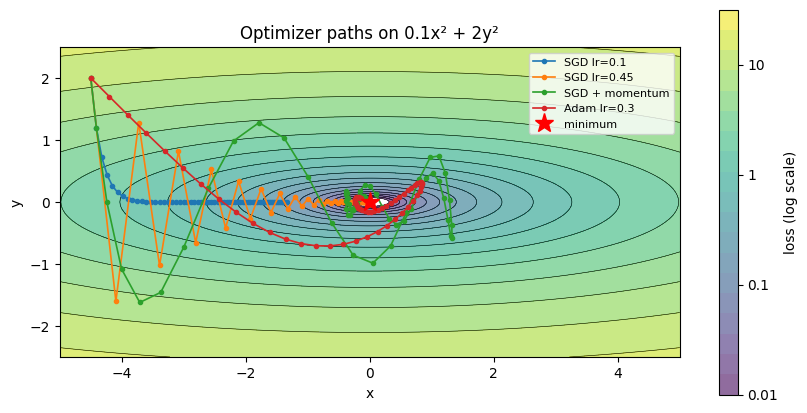

In [11]:
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


def loss_fn(w):
    x, y = w
    return 0.1 * x**2 + 2 * y**2


def run(make_opt, steps=60):
    w = torch.tensor([-4.5, 2.0], requires_grad=True)
    opt = make_opt([w])
    path = [w.detach().clone()]
    for _ in range(steps):
        loss = loss_fn(w)
        opt.zero_grad(); loss.backward(); opt.step()
        path.append(w.detach().clone())
    return torch.stack(path).numpy()


optimizers = [
    ("SGD lr=0.1",     lambda p: torch.optim.SGD(p, lr=0.1)),
    ("SGD lr=0.45",    lambda p: torch.optim.SGD(p, lr=0.45)),
    ("SGD + momentum", lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9)),
    ("Adam lr=0.3",    lambda p: torch.optim.Adam(p, lr=0.3, betas=(0.9, 0.999))),
]

# landscape: evaluate the SAME loss_fn on a grid covering every path
X, Y = torch.meshgrid(torch.linspace(-5, 5, 300), torch.linspace(-2.5, 2.5, 300), indexing="xy")
Z = loss_fn(torch.stack([X, Y]))
levels = torch.logspace(-2, 1.5, 20).numpy()   # dense near the minimum, sparse up the walls

fig, ax = plt.subplots(figsize=(10, 5))
cf = ax.contourf(X, Y, Z, levels=levels, norm=LogNorm(), cmap="viridis", alpha=0.6)
ax.contour(X, Y, Z, levels=levels, colors="k", linewidths=0.4)
fig.colorbar(cf, ax=ax, label="loss (log scale)", ticks=[0.01, 0.1, 1, 10], format="%g")

for label, make_opt in optimizers:
    p = run(make_opt)
    ax.plot(p[:, 0], p[:, 1], "o-", ms=3, lw=1.2, label=label)

ax.plot(0, 0, "r*", ms=14, label="minimum")
ax.set_aspect("equal")                         # true proportions: 20x steeper in y
ax.set_xlim(-5, 5); ax.set_ylim(-2.5, 2.5)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Optimizer paths on 0.1x² + 2y²")
plt.show()

## 7. Results log

| Run | Change | Epochs | Best val acc |
|---|---|---|---|
| run0 | no BatchNorm | 30 | 0.050 (stuck at chance, loss = ln 20) |
| run1_bn | + BatchNorm | 30 | **0.759** |
| run2 | + dropout 0.5 | | |
| run3 | 50 epochs | | |